# ChronoState-KD Lite — Phase 4: Markov layer + hybrid router

**Goal:** route each user turn to an adapter with `score_j = β·softmax(cos/τ)_j + (1−β)·T[prev, j]`, and measure what the Markov prior buys over a pure semantic classifier (β = 1).

**Runtime: CPU is enough** (bge-small, 33 M params). No GPU needed — run on a plain Colab CPU runtime or locally.

**Gate to pass before Phase 5:** on 40 synthetic conversations × 6 turns with 30 % follow-up turns, β = 0.7 has **fewer unnecessary jumps** and **equal or higher accuracy** than β = 1.

Edit `GITHUB_URL`.

In [1]:
GITHUB_URL = "https://github.com/DhanushGD/chronostate-kd.git"   # <-- edit
REPO_DIR   = "/content/chronostate-kd"
DRIVE_ROOT = "/content/drive/MyDrive/chronostate"
BETAS = [1.0, 0.9, 0.7, 0.5]


## 1. Setup

In [2]:
import os, json, time, torch
if not os.path.exists(REPO_DIR):
    !git clone $GITHUB_URL $REPO_DIR
%cd $REPO_DIR
!git pull --ff-only
!pip install -q -r requirements.txt && pip install -q -e .
try:
    from google.colab import drive; drive.mount("/content/drive")
    EVENTS = f"{DRIVE_ROOT}/results/events.jsonl"
except Exception:
    EVENTS = "results/events.jsonl"          # running locally
from chronostate.config import load_config
from chronostate.monitor import Monitor
from chronostate.router import HybridRouter, build_prototypes, make_st_embedder
from chronostate.routing_eval import make_conversations, run_routing_eval
from chronostate.data import load_domain_rows
cfg = load_config("configs/lite.yaml")
mon = Monitor(EVENTS, run="phase4-router")


Cloning into '/content/chronostate-kd'...
remote: Enumerating objects: 95, done.
remote: Counting objects: 100% (95/95), done.
remote: Compressing objects: 100% (72/72), done.
remote: Total 95 (delta 31), reused 84 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (95/95), 351.02 KiB | 23.40 MiB/s, done.
Resolving deltas: 100% (31/31), done.
/content/chronostate-kd
Already up to date.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for chronostate-kd (pyproject.toml) ... done
Mounted at /content/drive


## 2. Prompt pools
**Prototypes** come from the first 200 *training* prompts per domain (the same rows the adapters were trained on). **Evaluation** prompts are held out: CodeFeedback rows beyond the training 1,500 and MBPP prompts for code; GSM8K *test* questions 100–600 for reasoning (the first 100 are reserved for the Phase 5 accuracy eval).

In [3]:
from datasets import load_dataset
t0 = time.time()
train_rows = {d: load_domain_rows(cfg, d) for d in ["code", "reasoning"]}
proto_prompts = {d: [r["prompt"] for r in train_rows[d][: cfg.router.prototypes_per_domain]] for d in train_rows}

cf = load_dataset("m-a-p/CodeFeedback-Filtered-Instruction", split="train")
seen = set(r["prompt"] for r in train_rows["code"])
code_held = [ex["query"].strip() for ex in cf.select(range(20000)) if str(ex["lang"]).lower() == "python" and ex["query"].strip() not in seen][:300]
mbpp = [ex["prompt"] for ex in load_dataset("google-research-datasets/mbpp", "sanitized", split="test")]
gsm_test = load_dataset("openai/gsm8k", "main", split="test")
pools = {"code": code_held + mbpp, "reasoning": [gsm_test[i]["question"] for i in range(100, 600)]}
print({k: len(v) for k, v in pools.items()}, f"({time.time()-t0:.0f}s)")


README.md:   0%|          | 0.00/2.93k [00:00<?, ?B/s]

CodeFeedback-Filtered-Instruction.jsonl: reconstructing file:   0%|          |  0.00B /  371MB            

CodeFeedback-Filtered-Instruction.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/156526 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

... (15 outputs left out)

Generating test split:   0%|          | 0/257 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/43 [00:00<?, ? examples/s]

Generating prompt split:   0%|          | 0/7 [00:00<?, ? examples/s]

{'code': 557, 'reasoning': 500} (31s)


## 3. Embedder + prototypes

In [4]:
embed = make_st_embedder(cfg.models.router_embedder, device="cpu")
t0 = time.time(); protos = build_prototypes(embed, proto_prompts); print(f"prototypes built in {time.time()-t0:.1f}s")
print("cos(code_proto, reasoning_proto) =", float(protos["code"] @ protos["reasoning"]))
# how separable are held-out prompts? raw cosine gap distribution per domain
import statistics
def gaps(prompts, own):
    e = torch.nn.functional.normalize(embed(prompts).float(), dim=-1)
    c = e @ torch.stack([protos["code"], protos["reasoning"]]).T
    own_i = 0 if own == "code" else 1
    return (c[:, own_i] - c[:, 1 - own_i]).tolist()
for d in pools:
    g = gaps(pools[d][:200], d)
    print(f"{d}: own-minus-other cosine gap  median {statistics.median(g):+.3f}  min {min(g):+.3f}  frac>0 {sum(x>0 for x in g)/len(g):.2f}")
from chronostate.routing_eval import FOLLOWUPS
g = gaps(FOLLOWUPS, "code"); print(f"follow-ups: |gap| median {statistics.median(abs(x) for x in g):.3f}  (should be ~0: no signal)")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

prototypes built in 134.1s
cos(code_proto, reasoning_proto) = 0.8299016356468201
code: own-minus-other cosine gap  median +0.134  min +0.018  frac>0 1.00
reasoning: own-minus-other cosine gap  median +0.123  min +0.014  frac>0 1.00
follow-ups: |gap| median 0.030  (should be ~0: no signal)


## 4. β sweep on synthetic conversations
Same 40 conversations for every β (seeded). `T` is learned online during the sweep for each router separately.

In [5]:
convs = make_conversations(pools, n_conv=40, turns=6, followup_frac=0.3, seed=0)
print("turns:", sum(len(c) for c in convs), " follow-ups:", sum(t.is_followup for c in convs for t in c),
      " true switches:", sum(t.label_changed for c in convs for t in c))
results, routers = {}, {}
for beta in BETAS:
    r = HybridRouter(embed, protos, beta=beta, stickiness=cfg.markov.stickiness, ema=cfg.markov.ema, cos_temperature=cfg.router.cos_temperature)
    m = run_routing_eval(r, convs); results[beta] = m; routers[beta] = r
    mon.log("routing_eval", **m)
    print(f"beta={beta:.1f}  acc {m['accuracy']:.3f}  follow-up acc {m['followup_accuracy']:.3f}  jumps {m['jumps']:3d} "
          f"(unnecessary {m['unnecessary_jumps']:3d}, missed {m['missed_switches']:2d})  jumps/conv {m['jumps_per_conv']:.2f}  {m['latency_p50_ms']:.1f} ms/turn")
b1, b7 = results[1.0], results[0.7]
gate = b7["unnecessary_jumps"] < b1["unnecessary_jumps"] and b7["accuracy"] >= b1["accuracy"]
print("GATE (beta=0.7 fewer unnecessary jumps and >= accuracy than beta=1):", "PASS" if gate else "FAIL")


turns: 240  follow-ups: 45  true switches: 54
beta=1.0  acc 0.900  follow-up acc 0.467  jumps  84 (unnecessary  36, missed  6)  jumps/conv 2.10  53.3 ms/turn
beta=0.9  acc 0.904  follow-up acc 0.489  jumps  82 (unnecessary  34, missed  6)  jumps/conv 2.05  55.0 ms/turn
beta=0.7  acc 0.954  follow-up acc 0.756  jumps  69 (unnecessary  18, missed  3)  jumps/conv 1.73  56.2 ms/turn
beta=0.5  acc 0.971  follow-up acc 0.867  jumps  64 (unnecessary  12, missed  2)  jumps/conv 1.60  59.4 ms/turn
GATE (beta=0.7 fewer unnecessary jumps and >= accuracy than beta=1): PASS


## 5. Learned transition matrix (β = 0.7) and one worked conversation

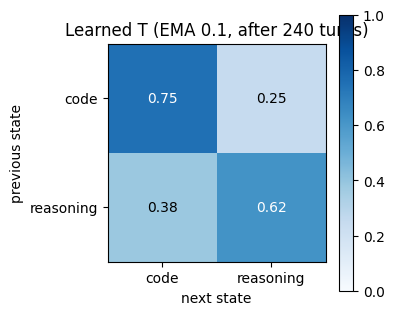

T: {
 "code": {
  "code": 0.7518614530563354,
  "reasoning": 0.2481384426355362
 },
 "reasoning": {
  "code": 0.381437748670578,
  "reasoning": 0.6185621023178101
 }
}

--- beta=1.0
JUMP ok  label=reasoning chosen=reasoning sem=0.83 prior=0.50 | There are 9,300 pennies in a cup. What is the total dollar a
     ok  label=reasoning chosen=reasoning sem=0.93 prior=0.82 | The tooth fairy left Sharon $5.00 in exchange for the first 
     ok  label=reasoning chosen=reasoning sem=0.62 prior=0.84 | [follow-up] what does that give?
JUMP ok  label=code      chosen=code      sem=0.90 prior=0.25 | Write a python function to find the sum of even factors of a
JUMP ERR label=code      chosen=reasoning sem=0.38 prior=0.72 | [follow-up] what does that give?
JUMP ok  label=code      chosen=code      sem=0.98 prior=0.32 | Write a Python program to split a given string into a list o

--- beta=0.7
JUMP ok  label=reasoning chosen=reasoning sem=0.83 prior=0.50 | There are 9,300 pennies in a cup. What is the 

In [6]:
import matplotlib.pyplot as plt, numpy as np
T = routers[0.7].transition_matrix(); doms = list(T)
M = np.array([[T[a][b] for b in doms] for a in doms])
fig, ax = plt.subplots(figsize=(4, 3.5)); im = ax.imshow(M, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(doms))); ax.set_yticks(range(len(doms))); ax.set_xticklabels(doms); ax.set_yticklabels(doms)
ax.set_xlabel("next state"); ax.set_ylabel("previous state"); ax.set_title("Learned T (EMA 0.1, after 240 turns)")
for i in range(len(doms)):
    for j in range(len(doms)): ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", color="white" if M[i,j] > 0.5 else "black")
os.makedirs("results", exist_ok=True); plt.colorbar(im); plt.tight_layout(); plt.savefig("results/phase4_transition_matrix.png", dpi=130); plt.show()
print("T:", json.dumps(T, indent=1))

# worked example: replay one conversation that contains follow-ups through beta=1 and beta=0.7
ex = next(c for c in convs if sum(t.is_followup for t in c) >= 2 and sum(t.label_changed for t in c) >= 1)
for beta in (1.0, 0.7):
    r = HybridRouter(embed, protos, beta=beta, cos_temperature=cfg.router.cos_temperature); print(f"\n--- beta={beta}")
    for t in ex:
        d = r.route(t.text)
        flag = "JUMP" if d.jumped else "    "
        ok = "ok " if d.chosen == t.label else "ERR"
        print(f"{flag} {ok} label={t.label:9s} chosen={d.chosen:9s} sem={d.cos_norm[t.label]:.2f} prior={d.prior[t.label]:.2f} | {'[follow-up] ' if t.is_followup else ''}{t.text[:60]}")


## 6. Routing-accuracy vs jumps plot + save

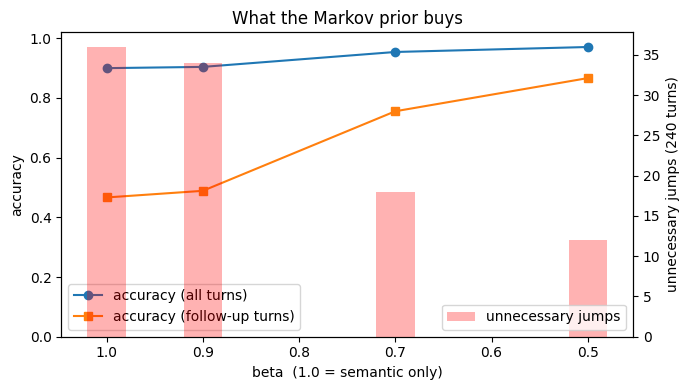

{
  "transition_matrix_beta0.7": {
    "code": {
      "code": 0.7518614530563354,
      "reasoning": 0.2481384426355362
    },
    "reasoning": {
      "code": 0.381437748670578,
      "reasoning": 0.6185621023178101
    }
  },
  "pools": {
    "code": 557,
    "reasoning": 500
  },
  "cos_proto_proto": 0.8299016356468201,
  "cos_temperature": 0.05,
  "gate_pass": true
}


In [7]:
fig, ax1 = plt.subplots(figsize=(7, 4))
bs = BETAS
ax1.plot(bs, [results[b]["accuracy"] for b in bs], "o-", label="accuracy (all turns)")
ax1.plot(bs, [results[b]["followup_accuracy"] for b in bs], "s-", label="accuracy (follow-up turns)")
ax1.set_xlabel("beta  (1.0 = semantic only)"); ax1.set_ylabel("accuracy"); ax1.set_ylim(0, 1.02); ax1.invert_xaxis()
ax2 = ax1.twinx(); ax2.bar(bs, [results[b]["unnecessary_jumps"] for b in bs], width=0.04, alpha=0.3, color="red", label="unnecessary jumps")
ax2.set_ylabel("unnecessary jumps (240 turns)")
ax1.legend(loc="lower left"); ax2.legend(loc="lower right"); ax1.set_title("What the Markov prior buys")
plt.tight_layout(); plt.savefig("results/phase4_beta_sweep.png", dpi=130); plt.show()
out = {"betas": results, "transition_matrix_beta0.7": T, "pools": {k: len(v) for k, v in pools.items()},
       "cos_proto_proto": float(protos["code"] @ protos["reasoning"]), "cos_temperature": cfg.router.cos_temperature, "gate_pass": bool(gate)}
json.dump(out, open("results/phase4_routing.json", "w"), indent=2)
torch.save({"prototypes": protos, "domains": list(protos), "embedder": cfg.models.router_embedder}, "results/prototypes.pt")
try: json.dump(out, open(f"{DRIVE_ROOT}/results/phase4_routing.json", "w"), indent=2); torch.save({"prototypes": protos, "domains": list(protos), "embedder": cfg.models.router_embedder}, f"{DRIVE_ROOT}/results/prototypes.pt")
except Exception as e: print("no drive:", e)
mon.close(); print(json.dumps({k: v for k, v in out.items() if k != "betas"}, indent=2))


## Gate checklist
- [ ] β = 0.7 has fewer unnecessary jumps than β = 1 and ≥ accuracy
- [ ] follow-up accuracy clearly higher at β = 0.7
- [ ] `results/phase4_routing.json`, `results/prototypes.pt`, `results/phase4_transition_matrix.png`, `results/phase4_beta_sweep.png` committed (`prototypes.pt` is tiny, ~3 KB, and Phase 5 loads it)

Report back: the four `beta=` lines, the gate line, the cosine-gap lines from cell 3.